#Dataset Characterization

In [ ]:
dataset_folder="path/2/dataset"
texts_folder="path/2/texts"

Inception projects folder and the languages to build the paths

In [ ]:
project_folder="path/2/project"
LANGUAGES=["PT","BG","EN","RU"]

In [ ]:
import os
import json

In [ ]:
with open(os.path.join(dataset_folder,"dataset_complete.json"), "r", newline="") as f:
    all_data=json.load(f)


In [ ]:
print(len(all_data))

1065


In [ ]:
#unique narratives
narratives=set()
for entry in all_data:
  narratives.add(entry["dom_narr"])
print(len(narratives))


22


Counter({'Other': 1,
         'URW: Hidden plots by secret schemes of powerful groups': 1,
         'CC: Green policies are geopolitical instruments': 1,
         'CC: Downplaying climate change': 1,
         'URW: Overpraising the West': 1,
         'CC: Amplifying Climate Fears': 1,
         'URW: Discrediting Ukraine': 1,
         'URW: Praise of Russia': 1,
         'URW: Russia is the Victim': 1,
         'CC: Criticism of climate policies': 1,
         'CC: Questioning the measurements and science': 1,
         'CC: Hidden plots by secret schemes of powerful groups': 1,
         'URW: Discrediting the West, Diplomacy': 1,
         'URW: Speculating war outcomes': 1,
         'CC: Criticism of climate movement': 1,
         'URW: Blaming the war on others rather than the invader': 1,
         'URW: Negative Consequences for the West': 1,
         'URW: Distrust towards Media': 1,
         'CC: Climate change is beneficial': 1,
         'CC: Criticism of institutions and authoritie

## Document and Evidence Tokens



In [ ]:
from transformers import AutoTokenizer

# create tokenizer for multilingual documents
tokenizer = AutoTokenizer.from_pretrained("bert-base-multilingual-cased")

In [ ]:
# Count the number of tokens in all documents
# Helper function to count tokens
def count_tokens(text):
    # Count all tokens without truncation
    return len(tokenizer.encode(text, add_special_tokens=True))





### Document

In [ ]:
token_counts = []
for entry in all_data:
    text = entry['text']
    num_tokens = count_tokens(text)
    entry['num_tokens'] = num_tokens # Add token count to each entry

In [ ]:
#plot tokens by language
import pandas as pd

df=pd.DataFrame.from_dict(all_data)
df=df[["doc_id","language","num_tokens"]]

In [ ]:
sum(df["num_tokens"])/len(df)

739.9737089201878

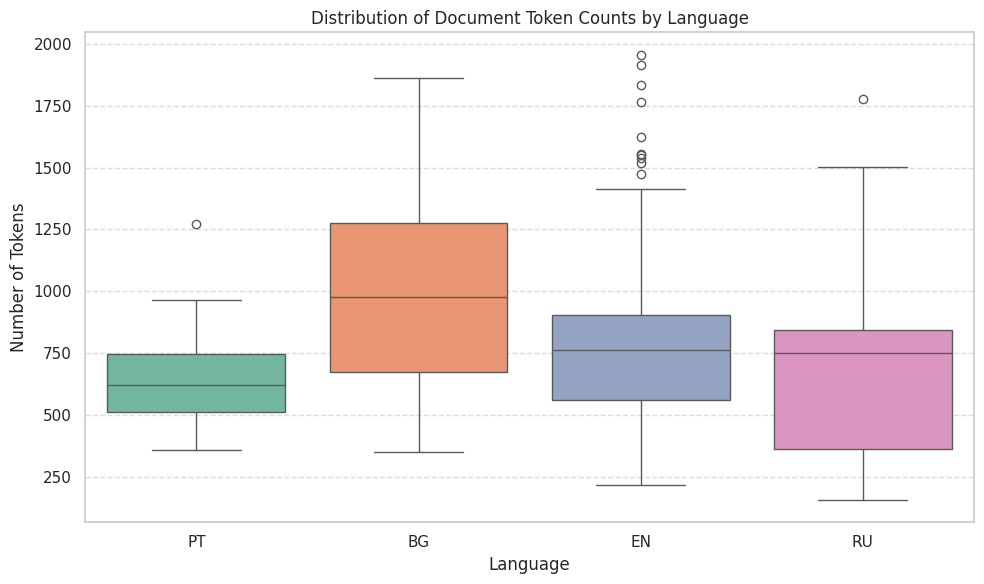

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Set figure size for better quality
plt.figure(figsize=(10, 6))

# Use 'hue' instead of 'color' to differentiate by language
ax = sns.boxplot(x="language", y="num_tokens", hue="language", data=df, palette="Set2")

# Add a title and improved labels
ax.set_title('Distribution of Document Token Counts by Language')
ax.set(xlabel='Language', ylabel='Number of Tokens')

# Add grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adjust layout to prevent labels from overlapping
plt.tight_layout()

plt.savefig("document_token_distribution.png")


# Display the plot
plt.show()

In [ ]:
#Average token per Document ID by language

df_agg=df.groupby(["doc_id","language"])



In [ ]:
# Calculate the average number of tokens per document aggregated by language
average_tokens_per_document_by_language = df.groupby('language')['num_tokens'].mean().reset_index()
average_tokens_per_document_by_language.rename(columns={'num_tokens': 'average_tokens_per_doc'}, inplace=True)

display(average_tokens_per_document_by_language)

,language,average_tokens_per_doc
0,BG,980.073394
1,EN,779.354430
2,PT,632.130919
3,RU,648.501992


### Evidence Tokens

In [ ]:
evidence_spans_per_language=list()
token_counts = []
for entry in all_data:
  for e in entry["evidence"]:
    temp=dict()
    text=entry["text"]
    span=text[e["begin"]:e["end"]]
    temp["span"]=span
    temp["language"]=entry["language"]
    temp["span_tokens"]=count_tokens(span)
    temp["doc_id"]=entry["doc_id"]
    temp["dom_narr"]=entry["dom_narr"]
    text = entry['text']
    num_tokens = count_tokens(text)
    temp['num_tokens_text'] = num_tokens # Add token count to each entry
    evidence_spans_per_language.append(temp)




In [ ]:
print(len(evidence_spans_per_language))

4348


In [ ]:
#show distribution of tokens in evidence per language
import pandas as pd

df=pd.DataFrame.from_dict(evidence_spans_per_language)
df["ratio_evidence_text"]=df["span_tokens"]/df["num_tokens_text"]*100


In [ ]:

df_agg=df[["language","ratio_evidence_text"]].groupby(["language"]).mean()
df_agg

,ratio_evidence_text
language,
BG,6.469689
EN,6.681756
PT,5.114953
RU,7.973737


In [ ]:
df=df[["language","span_tokens"]]
df_agg=df.groupby(["language"]).mean()
df_agg.rename(columns={'span_tokens': 'average_tokens_per_span'}, inplace=True)
df_agg


,average_tokens_per_span
language,
BG,58.923841
EN,48.719697
PT,31.558650
RU,48.103882


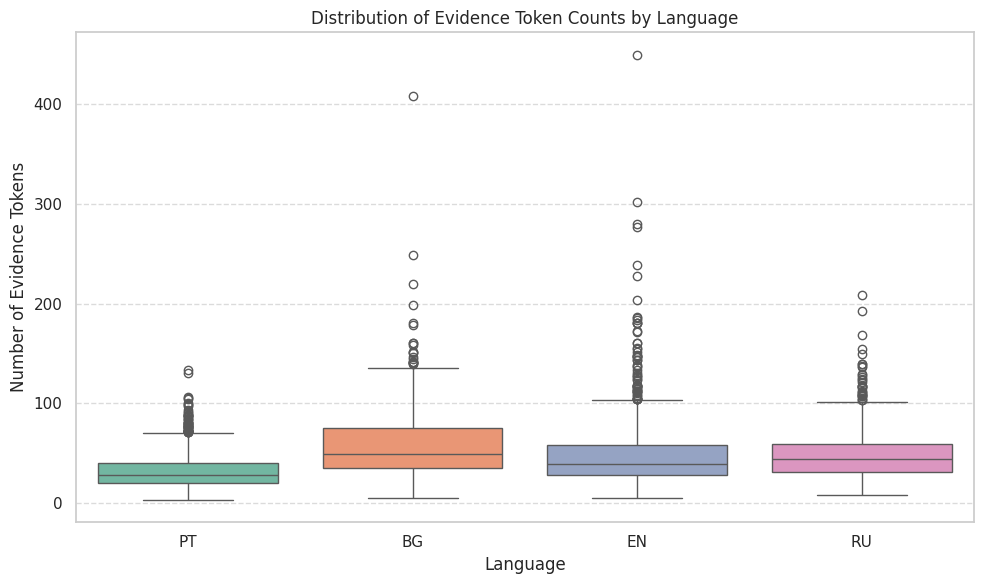

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Set figure size for better quality
plt.figure(figsize=(10, 6))

# Use 'hue' instead of 'color' to differentiate by language
ax = sns.boxplot(x="language", y="span_tokens", hue="language", data=df, palette="Set2")

# Add a title and improved labels
ax.set_title('Distribution of Evidence Token Counts by Language')
ax.set(xlabel='Language', ylabel='Number of Evidence Tokens')

# Add grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adjust layout to prevent labels from overlapping
plt.tight_layout()

# Save the plot to a file
plt.savefig("evidence_token_distribution.png")

# Display the plot
plt.show()

In [ ]:
#Average evidence per Document ID by language

df_agg=df.groupby(["doc_id","language"])

evidence_counts_per_doc = df_agg.size().reset_index(name='num_evidence_spans')
# Calculate the average number of evidence spans per document, aggregated by language
average_evidence_per_language = evidence_counts_per_doc.groupby('language')['num_evidence_spans'].mean().reset_index()
average_evidence_per_language.rename(columns={'num_evidence_spans': 'average_spans_per_doc'}, inplace=True)
average_evidence_per_language

,language,average_spans_per_doc
0,BG,2.770642
1,EN,3.898734
2,PT,5.200557
3,RU,3.796813


#Dominant Narrative Analysis

In [ ]:
all_data[601]

{'doc_id': 'EN_CC_100004.txt',
 'text': 'A Tesla Owner Just Exposed A Sick Secret About Electric Cars… \n\n A Tesla Owner Just Exposed A Sick Secret About Electric Cars…\n\nThe left has been preaching global warming, cooling, climate change, and end-of-the-world nonsense since before many of us were born.\n\nIn his book An Inconvenient Truth: The Crisis of Global Warming, Al Gore attempted to persuade everyone that the globe was overheating.\n\nDemocrats are always negotiating deals that place the United States at a competitive disadvantage with other countries, some of whom are our foes, such as Communist China.\n\nThey manipulate children into doing their bidding by convincing them that they only have a few years to live.\n\nFor them, it’s a pretty decent racket. However, there is another viewpoint.\n\nEconomic observers have long known that there are no free lunches, and perhaps it’s time that electric-car fans did as well.\n\nLeftists extol Teslas and other electric cars as cure-al

In [ ]:



#Aggregate Narrative per Language
df=pd.DataFrame.from_dict(all_data)
df=df[["doc_id","language","dom_narr"]]
df_agg=df.groupby(["language","dom_narr"])
df_agg.size().reset_index(name='count')


,language,dom_narr,count
0,BG,CC: Amplifying Climate Fears,64
1,BG,CC: Climate change is beneficial,1
2,BG,CC: Controversy about green technologies,3
3,BG,CC: Criticism of climate policies,8
4,BG,CC: Criticism of institutions and authorities,11
...,...,...,...
66,RU,URW: Hidden plots by secret schemes of powerfu...,3
67,RU,URW: Negative Consequences for the West,1
68,RU,URW: Praise of Russia,83
69,RU,URW: Russia is the Victim,13


### Average Evidence per Narrative per Language

In [ ]:
df=pd.DataFrame.from_dict(evidence_spans_per_language)
df_agg=df.groupby(["language","dom_narr","doc_id"])
df_agg.size().reset_index(name='num_evidence_spans')
#average of num_evidence_span per language


,language,dom_narr,doc_id,num_evidence_spans
0,BG,CC: Amplifying Climate Fears,A5_CC_BG_10017.txt,8
1,BG,CC: Amplifying Climate Fears,A5_CC_BG_10096.txt,2
2,BG,CC: Amplifying Climate Fears,A5_CC_BG_10174.txt,1
3,BG,CC: Amplifying Climate Fears,A5_CC_BG_10207.txt,4
4,BG,CC: Amplifying Climate Fears,A5_CC_BG_10220.txt,2
...,...,...,...,...
1060,RU,URW: Russia is the Victim,RU-URW-1218.txt,7
1061,RU,URW: Russia is the Victim,RU-URW-1322.txt,2
1062,RU,URW: Speculating war outcomes,RU-URW-1103.txt,4
1063,RU,URW: Speculating war outcomes,RU-URW-1144.txt,10


In [ ]:
# First, count the number of evidence spans for each document within each narrative
evidence_counts_per_doc_narrative = df.groupby(['language', 'dom_narr', 'doc_id']).size().reset_index(name='num_evidence_spans')
evidence_counts_per_doc_narrative


,language,dom_narr,doc_id,num_evidence_spans
0,BG,CC: Amplifying Climate Fears,A5_CC_BG_10017.txt,8
1,BG,CC: Amplifying Climate Fears,A5_CC_BG_10096.txt,2
2,BG,CC: Amplifying Climate Fears,A5_CC_BG_10174.txt,1
3,BG,CC: Amplifying Climate Fears,A5_CC_BG_10207.txt,4
4,BG,CC: Amplifying Climate Fears,A5_CC_BG_10220.txt,2
...,...,...,...,...
1060,RU,URW: Russia is the Victim,RU-URW-1218.txt,7
1061,RU,URW: Russia is the Victim,RU-URW-1322.txt,2
1062,RU,URW: Speculating war outcomes,RU-URW-1103.txt,4
1063,RU,URW: Speculating war outcomes,RU-URW-1144.txt,10


In [ ]:
# Then, calculate the average number of evidence spans per document for each language and dominant narrative
average_evidence_per_narrative_per_language = evidence_counts_per_doc_narrative.groupby(['language', 'dom_narr'])['num_evidence_spans'].mean().reset_index()
average_evidence_per_narrative_per_language.rename(columns={'num_evidence_spans': 'average_spans_per_doc'}, inplace=True)

display(average_evidence_per_narrative_per_language)

,language,dom_narr,average_spans_per_doc
0,BG,CC: Amplifying Climate Fears,3.375000
1,BG,CC: Climate change is beneficial,3.000000
2,BG,CC: Controversy about green technologies,2.333333
3,BG,CC: Criticism of climate policies,2.000000
4,BG,CC: Criticism of institutions and authorities,2.909091
...,...,...,...
66,RU,URW: Hidden plots by secret schemes of powerfu...,5.000000
67,RU,URW: Negative Consequences for the West,2.000000
68,RU,URW: Praise of Russia,4.036145
69,RU,URW: Russia is the Victim,3.538462


#Example for Paper

In [ ]:
#609
example_id=618
example_text=all_data[int(example_id)]["text"]
print(all_data[int(example_id)]["dom_narr"])
example_text


CC: Downplaying climate change


'Math Confirms Foolishness of Warming Alarm \n\n The science of climate change often is presented in complicated language that speaks of computer models and the theoretical inputs and outputs thereof and concludes that the globe is on the verge of “boiling.” Well, leave it to three physicists -- steeped in calculus and such arcane matters as the behavior of molecules and the nuclear charge of atoms -- to simplify the analysis and arrive at a much less alarming determination.\n\n“Straightforward calculations … show that eliminating U.S. CO2 emissions by the year 2050 would avoid a temperature increase of 0.0084 degrees Celsius,” states a brief paper authored by Drs. Richard Lindzen, Massachusetts Institute of Technology; William Happer, Princeton University; and William A. van Wijngaarden, York University, Toronto. On the Fahrenheit scale, the value of averted warming is 0.015 ◦F degrees.\n\nIn short, the amount of warming averted by eliminating CO2 emissions in the United States would 

In [ ]:
for e in all_data[example_id]["evidence"]:
  print(example_text[e["begin"]:e["end"]])
  print("-------------------------------")

Straightforward calculations … show that eliminating U.S. CO2 emissions by the year 2050 would avoid a temperature increase of 0.0084 degrees Celsius,” states a brief paper authored by Drs. Richard Lindzen, Massachusetts Institute of Technology; William Happer, Princeton University; and William A. van Wijngaarden, York University, Toronto. On the Fahrenheit scale, the value of averted warming is 0.015 ◦F degrees.
-------------------------------
In short, the amount of warming averted by eliminating CO2 emissions in the United States would be too small to measure.
-------------------------------
